In [2]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("churn.db")
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)
print(tables)

Empty DataFrame
Columns: [name]
Index: []


In [3]:
import os
print(os.getcwd())
print(os.listdir())

c:\Users\HP\OneDrive\Desktop\churn project\notebooks
['01_cleaning.ipynb', '02_sql_analysis.ipynb', '03_model_training.ipynb', 'churn.db']


In [4]:
import os
print(os.listdir(".."))

['app', 'data', 'models', 'notebooks', 'screenshot', 'sql', 'venv']


In [5]:
print(os.listdir("../data"))

['churn.db', 'Telco-Customer-Churn.csv', 'telco_clean.csv']


Best threshold: 0.05 | Max profit: $29,670


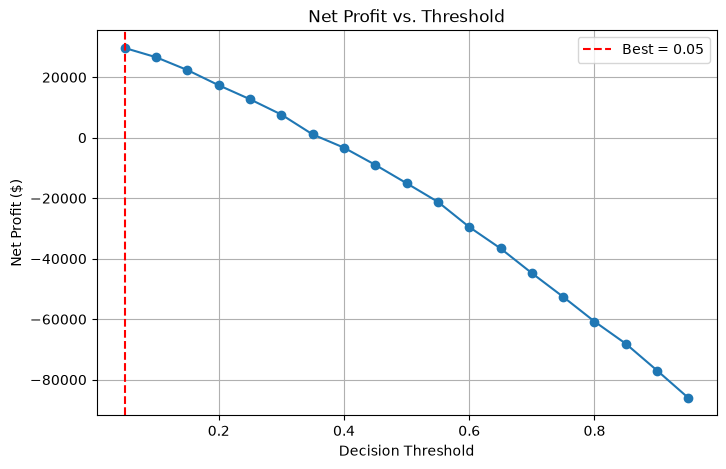

Test profit at 0.05: $7,065


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.metrics import confusion_matrix
from xgboost import XGBClassifier

df = pd.read_csv("../data/telco_clean.csv")
df = df.drop(columns=[c for c in df.columns if c.lower() == "customerid"])
y = df["Churn"].map({"Yes": 1, "No": 0}) if df["Churn"].dtype == object else df["Churn"]
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = XGBClassifier(eval_metric="logloss", random_state=42)
y_prob = cross_val_predict(model, X_train, y_train, cv=5, method="predict_proba")[:, 1]

def profit(y_true, p, t):
    tn, fp, fn, tp = confusion_matrix(y_true, (p >= t).astype(int)).ravel()
    return tp * 50 - fp * 15 - fn * 65

thresholds = np.arange(0.05, 0.96, 0.05)
profits = [profit(y_train, y_prob, t) for t in thresholds]
best_t = thresholds[int(np.argmax(profits))]
print(f"Best threshold: {best_t:.2f} | Max profit: ${max(profits):,.0f}")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, profits, marker="o")
plt.axvline(best_t, color="red", linestyle="--", label=f"Best = {best_t:.2f}")
plt.xlabel("Decision Threshold")
plt.ylabel("Net Profit ($)")
plt.title("Net Profit vs. Threshold")
plt.legend()
plt.grid(True)
plt.savefig("../screenshot/profit_vs_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

model.fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]
print(f"Test profit at {best_t:.2f}: ${profit(y_test, p_test, best_t):,.0f}")

In [9]:
SUCCESS = 0.6   # मान रहे हैं 60% flagged churners offer से रुक जाते हैं

def profit(y_true, p, t):
    tn, fp, fn, tp = confusion_matrix(y_true, (p >= t).astype(int)).ravel()
    return tp * (SUCCESS * 65 - 15) - fp * 15

thresholds = np.arange(0.02, 0.96, 0.01)

Best threshold: 0.39 | Max profit: $11,754


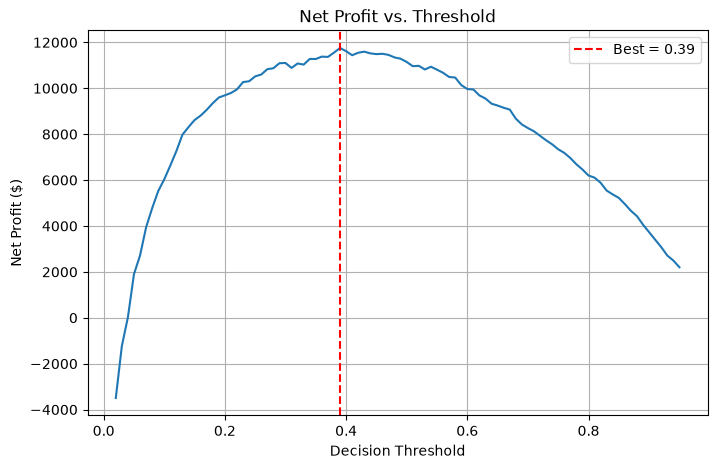

Test profit at 0.39: $2,637


In [10]:
profits = [profit(y_train, y_prob, t) for t in thresholds]
best_t = thresholds[int(np.argmax(profits))]
print(f"Best threshold: {best_t:.2f} | Max profit: ${max(profits):,.0f}")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, profits)
plt.axvline(best_t, color="red", linestyle="--", label=f"Best = {best_t:.2f}")
plt.xlabel("Decision Threshold")
plt.ylabel("Net Profit ($)")
plt.title("Net Profit vs. Threshold")
plt.legend()
plt.grid(True)
plt.savefig("../screenshot/profit_vs_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Test profit at {best_t:.2f}: ${profit(y_test, p_test, best_t):,.0f}")